# Data Reduction: PCA & Numerosity Reduction

**Input:** `output/integrated_daily.parquet` (hasil `data_integration.ipynb`), dengan 1 baris = 1 hari × 1 borough dan 21 fitur numerik yang sudah bebas redundansi.

| Jenis reduksi | Teknik | Bagian |
|---|---|---|
| **Dimensionality reduction** | Low-variance filter, **PCA** | 2, 4 |
| Pembanding | PCA vs feature selection (hasil integrasi) | 5 |
| **Numerosity reduction** | Agregasi mingguan, stratified sampling | 6 |

Di akhir notebook ada **kesimpulan seluruh tugas** (bagian 8) dan **checklist kriteria tugas** (bagian 9).

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold"})

OUT_DIR, FIG_DIR = Path("output"), Path("figures")
FIG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

BORO_NAME = {"B": "Brooklyn", "M": "Manhattan", "Q": "Queens", "S": "Staten Island", "X": "Bronx"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]
SEASON_COLOR = {"Winter": "#2c7fb8", "Spring": "#27ae60", "Summer": "#e67e22", "Fall": "#8e44ad"}

## 1. Load Data Hasil Integrasi

In [2]:
data = pd.read_parquet(OUT_DIR / "integrated_daily.parquet")
data_full = pd.read_parquet(OUT_DIR / "integrated_daily_full.parquet")

META = ["date", "Boro", "month", "dow", "is_weekend", "season", "no_reports", "precip_corrected"]
FEATURES = [c for c in data.columns if c not in META]
FEATURES_FULL = [c for c in data_full.columns if c not in META]

print("Data:", data.shape, "| fitur numerik:", len(FEATURES))
print("Kolom identitas/kategori (tidak masuk PCA):", META)

Data: (12650, 29) | fitur numerik: 21
Kolom identitas/kategori (tidak masuk PCA): ['date', 'Boro', 'month', 'dow', 'is_weekend', 'season', 'no_reports', 'precip_corrected']


PCA hanya bekerja pada fitur **numerik kontinu**. Tanggal, kode borough, musim, dan flag tidak dimasukkan. Kolom-kolom ini dipakai untuk **mewarnai** hasil PCA agar bisa diinterpretasi.

## 2. Persiapan Data untuk PCA

### 2.1 Low-variance filter
Fitur yang hampir selalu bernilai sama tidak membawa informasi. Setelah standardisasi, variasi kecilnya justru **dibesar-besarkan** hingga setara fitur lain. Aturannya: buang fitur yang **satu nilainya muncul di > 95% baris**.

In [3]:
mode_share = data[FEATURES].apply(lambda s: s.value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
lv = pd.DataFrame({"porsi nilai terbanyak": mode_share,
                   "nilai terbanyak": data[FEATURES].mode().iloc[0][mode_share.index],
                   "dibuang": mode_share > 0.95})
display(lv.head(6))

LOW_VAR = lv.index[lv["dibuang"]].tolist()
PCA_FEATURES = [f for f in FEATURES if f not in LOW_VAR]
print(f"Dibuang (low variance): {LOW_VAR} → {len(FEATURES)} → {len(PCA_FEATURES)} fitur")

,porsi nilai terbanyak,nilai terbanyak,dibuang
pct_repair_outlier,0.989,0.000,True
snow,0.939,0.000,False
freeze_thaw,0.811,0.000,False
snow_7d,0.755,0.000,False
pct_same_day,0.728,0.000,False
freeze_thaw_28d,0.549,0.000,False


Dibuang (low variance): ['pct_repair_outlier'] → 21 → 20 fitur


`pct_repair_outlier` bernilai 0 di hampir 99% hari-borough (outlier durasi memang jarang), sehingga dibuang. `snow` (±94% nol) **dipertahankan** karena masih di bawah ambang dan hari bersalju memang informatif.

### 2.2 Winsorizing & transformasi log

PCA berbasis **variansi**, sehingga sangat sensitif terhadap nilai ekstrem dan distribusi miring.

| Perlakuan | Fitur | Alasan |
|---|---|---|
| **Winsorize p99** | `median_repair_days`, `mean_shape_len_m` | Nilai ekstrem yang valid (dipertahankan di cleaning) dipangkas **hanya untuk PCA** |
| **log1p** | fitur **jumlah/besaran** yang skewed: `n_reports`, `median_repair_days`, `mean_shape_len_m`, `precip`, `snow`, `precip_7d`, `snow_7d`, `precip_lag1`, `precip_lag3` | Memampatkan ekor panjang; `log1p` aman untuk nilai 0 |
| **Tidak ditransformasi** | proporsi (`pct_*`), biner (`freeze_thaw`), suhu, `freeze_thaw_28d` | Proporsi sudah terbatas 0–1 dan biner hanya 0/1, sehingga log tidak bermakna. Suhu bisa negatif dan tidak skewed |

In [4]:
WINSOR = ["median_repair_days", "mean_shape_len_m"]
LOG_COLS = ["n_reports", "median_repair_days", "mean_shape_len_m", "precip", "snow",
            "precip_7d", "snow_7d", "precip_lag1", "precip_lag3"]

def prepare(frame, features):
    X = frame[features].astype(float).copy()
    for c in [c for c in WINSOR if c in X]:
        X[c] = X[c].clip(upper=X[c].quantile(0.99))
    lc = [c for c in LOG_COLS if c in X]
    X[lc] = np.log1p(X[lc])
    return X

X_raw = data[PCA_FEATURES].astype(float)
X_prep = prepare(data, PCA_FEATURES)

skew = pd.DataFrame({"skew sebelum": X_raw.skew(), "skew sesudah": X_prep.skew()})
skew["ditransformasi"] = skew.index.isin(LOG_COLS)
skew.sort_values("skew sebelum", key=abs, ascending=False).round(2)

,skew sebelum,skew sesudah,ditransformasi
snow,13.140,7.020,True
mean_shape_len_m,6.610,-0.550,True
snow_7d,5.300,2.790,True
precip_lag3,4.050,1.180,True
precip_lag1,4.050,1.170,True
precip,4.050,1.170,True
pct_same_day,3.010,3.010,False
median_repair_days,2.490,0.830,True
n_reports,2.080,-0.330,True
pct_by_ONF,1.730,1.730,False


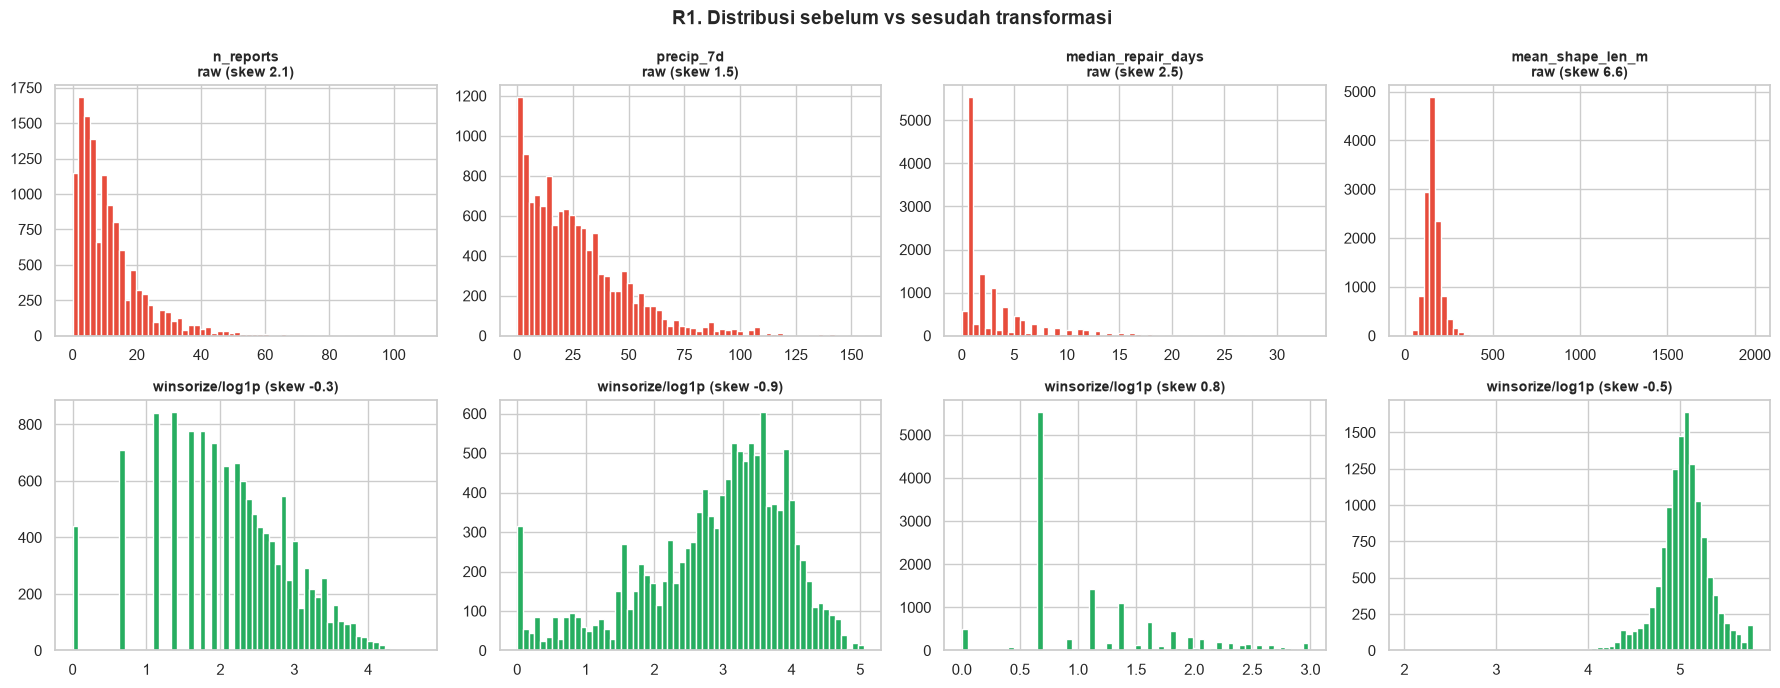

In [5]:
SHOW = ["n_reports", "precip_7d", "median_repair_days", "mean_shape_len_m"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, c in enumerate(SHOW):
    axes[0, j].hist(X_raw[c], bins=60, color="#e74c3c")
    axes[0, j].set_title(f"{c}\nraw (skew {X_raw[c].skew():.1f})", fontsize=10)
    axes[1, j].hist(X_prep[c], bins=60, color="#27ae60")
    axes[1, j].set_title(f"winsorize/log1p (skew {X_prep[c].skew():.1f})", fontsize=10)
fig.suptitle("R1. Distribusi sebelum vs sesudah transformasi", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("R1_transform_before_after")
plt.show()

### 2.3 Standardisasi (z-score)

$$z = \frac{x - \mu}{\sigma}$$

Setelah standardisasi, setiap fitur memiliki mean 0 dan standar deviasi 1, sehingga **bobotnya setara** di PCA terlepas dari satuannya (°C, mm, meter, proporsi, jumlah laporan).

In [6]:
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X_prep), columns=PCA_FEATURES, index=data.index)
print("mean min/max:", Z.mean().min().round(6), Z.mean().max().round(6))
print("std  min/max:", Z.std(ddof=0).min().round(6), Z.std(ddof=0).max().round(6))

mean min/max: -0.0 0.0
std  min/max: 1.0 1.0


## 3. Mengapa Scaling Wajib: PCA Tanpa vs Dengan Standardisasi

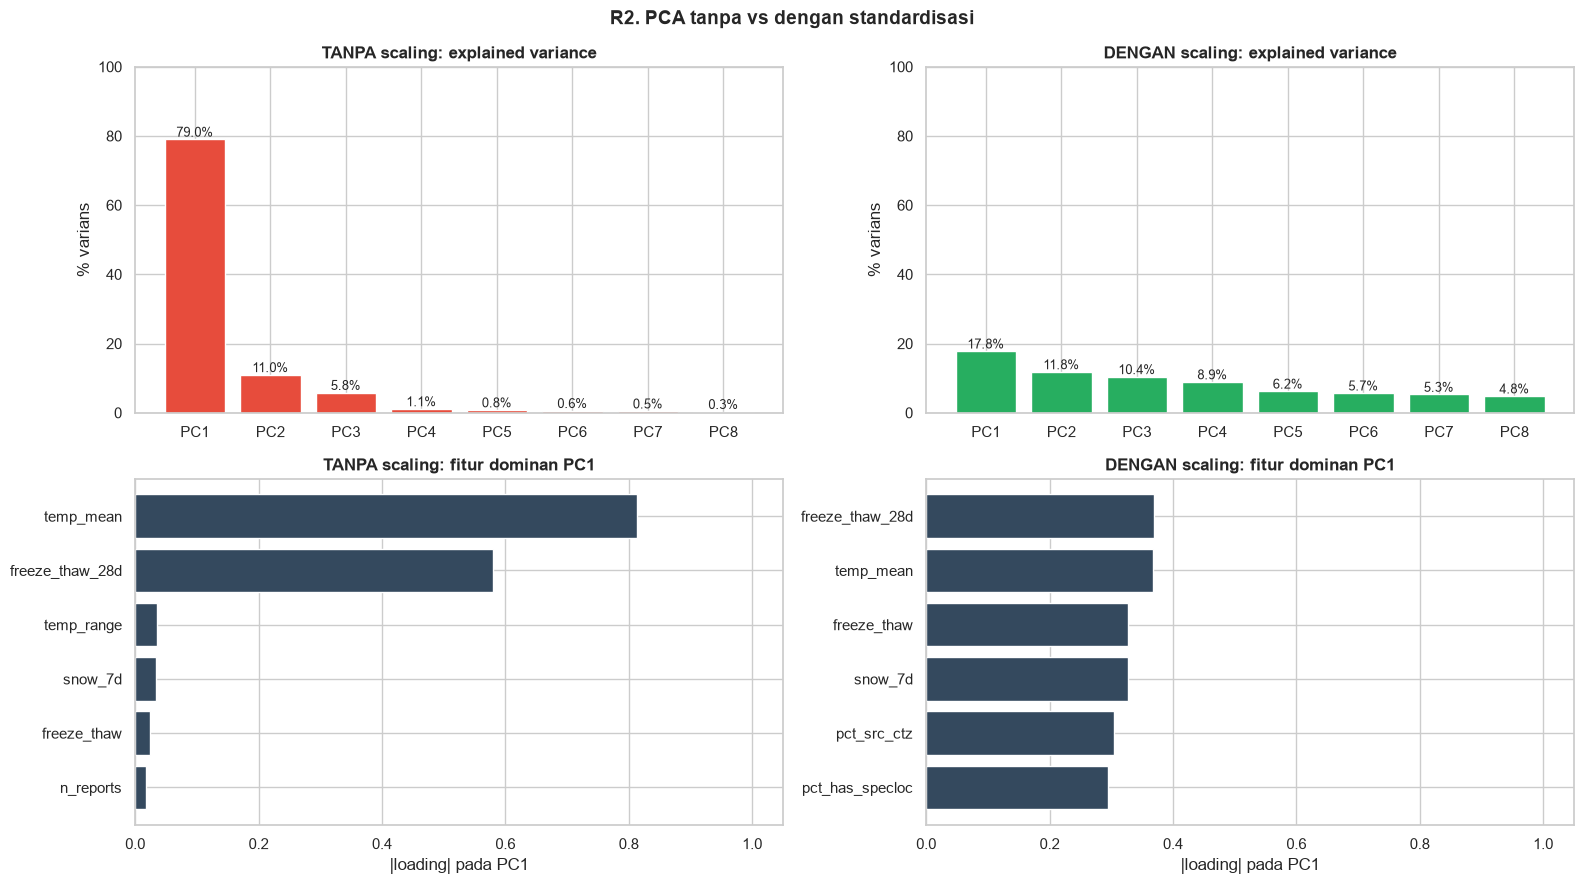

Variansi fitur (setelah log): {'temp_mean': 85.34, 'freeze_thaw_28d': 51.31, 'temp_range': 9.47}


In [7]:
pca_unscaled = PCA().fit(X_prep - X_prep.mean())
pca_scaled   = PCA().fit(Z)

top_unscaled = pd.Series(pca_unscaled.components_[0], index=PCA_FEATURES).abs().sort_values(ascending=False)
top_scaled   = pd.Series(pca_scaled.components_[0], index=PCA_FEATURES).abs().sort_values(ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for col, (name, p, top) in enumerate([("TANPA scaling", pca_unscaled, top_unscaled),
                                       ("DENGAN scaling", pca_scaled, top_scaled)]):
    r = p.explained_variance_ratio_[:8] * 100
    axes[0, col].bar([f"PC{i+1}" for i in range(8)], r, color="#e74c3c" if col == 0 else "#27ae60")
    axes[0, col].bar_label(axes[0, col].containers[0], fmt="%.1f%%", fontsize=9)
    axes[0, col].set_ylabel("% varians"); axes[0, col].set_ylim(0, 100)
    axes[0, col].set_title(f"{name}: explained variance")
    axes[1, col].barh(top.index[:6][::-1], top.values[:6][::-1], color="#34495e")
    axes[1, col].set_xlim(0, 1.05); axes[1, col].set_xlabel("|loading| pada PC1")
    axes[1, col].set_title(f"{name}: fitur dominan PC1")
fig.suptitle("R2. PCA tanpa vs dengan standardisasi", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("R2_pca_scaled_vs_unscaled")
plt.show()

print("Variansi fitur (setelah log):", X_prep.var().sort_values(ascending=False).head(3).round(2).to_dict())

**Tanpa scaling**, PC1 seolah menjelaskan sekitar 79% varians. Namun isinya **didominasi dua fitur** dengan variansi terbesar, yaitu `temp_mean` (°C, variansi ±85) dan `freeze_thaw_28d` (jumlah hari, variansi ±51). Keduanya dominan karena satuannya menghasilkan angka besar, bukan karena paling informatif. Fitur proporsi (variansi < 0,1) praktis tidak berperan. **Dengan scaling**, varians tersebar ke beberapa komponen dan PC1 merupakan kombinasi banyak fitur. Karena itu PCA selanjutnya **selalu memakai data terstandardisasi**.

## 4. PCA

### 4.1 Eigenvalue & explained variance

In [8]:
pca = pca_scaled
eig = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "% varians": pca.explained_variance_ratio_ * 100,
    "% kumulatif": pca.explained_variance_ratio_.cumsum() * 100,
}, index=[f"PC{i+1}" for i in range(len(PCA_FEATURES))])
eig

,eigenvalue,% varians,% kumulatif
PC1,3.559,17.791,17.791
PC2,2.361,11.805,29.597
PC3,2.079,10.393,39.990
PC4,1.780,8.899,48.888
PC5,1.243,6.217,55.105
PC6,1.134,5.669,60.774
PC7,1.058,5.288,66.063
PC8,0.964,4.818,70.880
PC9,0.922,4.612,75.492
PC10,0.837,4.183,79.676


### 4.2 Menentukan jumlah komponen (k): 3 kriteria

| Kriteria | Aturan |
|---|---|
| **Cumulative variance** | k terkecil dengan varians kumulatif ≥ 90% |
| **Kaiser** | Ambil komponen dengan eigenvalue > 1 (menjelaskan lebih dari 1 fitur asli) |
| **Elbow** | Titik "siku" pada scree plot, dicari otomatis dengan metode *kneedle* (jarak terjauh ke garis lurus dari PC pertama ke terakhir) |

In [9]:
cum = eig["% kumulatif"].values
k_cum90 = int(np.argmax(cum >= 90) + 1)
k_cum80 = int(np.argmax(cum >= 80) + 1)
k_kaiser = int((eig["eigenvalue"] > 1).sum())

# Kneedle: jarak tiap titik scree ke garis lurus PC1 → PC terakhir
x = np.arange(1, len(eig) + 1); y = eig["eigenvalue"].values
line = y[0] + (y[-1] - y[0]) * (x - 1) / (x[-1] - 1)
k_elbow = int(x[np.argmax(line - y)])

criteria = pd.DataFrame({
    "kriteria": ["Cumulative ≥ 90%", "Cumulative ≥ 80% (pembanding)", "Kaiser (eigenvalue > 1)", "Elbow (kneedle)"],
    "k": [k_cum90, k_cum80, k_kaiser, k_elbow],
})
criteria["% varians dipertahankan"] = [cum[k - 1] for k in criteria["k"]]
criteria["reduksi dimensi"] = [f"{len(PCA_FEATURES)} → {k}" for k in criteria["k"]]
criteria.round(1)

,kriteria,k,% varians dipertahankan,reduksi dimensi
0,Cumulative ≥ 90%,14,91.400,20 → 14
1,Cumulative ≥ 80% (pembanding),11,83.600,20 → 11
2,Kaiser (eigenvalue > 1),7,66.100,20 → 7
3,Elbow (kneedle),5,55.100,20 → 5


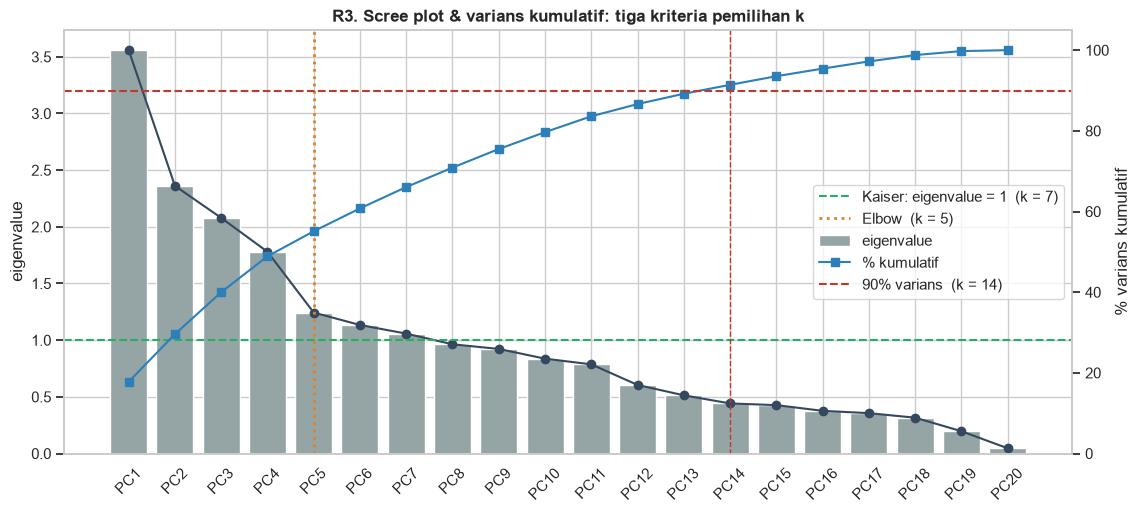

In [10]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(eig.index, eig["eigenvalue"], color="#95a5a6", label="eigenvalue")
ax.plot(eig.index, eig["eigenvalue"], "o-", color="#34495e")
ax.axhline(1, color="#27ae60", ls="--", lw=1.5, label=f"Kaiser: eigenvalue = 1  (k = {k_kaiser})")
ax.axvline(k_elbow - 1, color="#e67e22", ls=":", lw=2, label=f"Elbow  (k = {k_elbow})")
ax.set_ylabel("eigenvalue")
ax2 = ax.twinx()
ax2.plot(eig.index, eig["% kumulatif"], "s-", color="#2c7fb8", label="% kumulatif")
ax2.axhline(90, color="#c0392b", ls="--", lw=1.5, label=f"90% varians  (k = {k_cum90})")
ax2.axvline(k_cum90 - 1, color="#c0392b", ls="--", lw=1)
ax2.set_ylim(0, 105); ax2.set_ylabel("% varians kumulatif"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")
ax.set_title("R3. Scree plot & varians kumulatif: tiga kriteria pemilihan k")
plt.setp(ax.get_xticklabels(), rotation=45)
savefig("R3_scree_cumulative")
plt.show()

### 4.3 Keputusan k

Ketiga kriteria memberi jawaban berbeda:
- **Elbow** dan **Kaiser** menyarankan sedikit komponen, cocok untuk **interpretasi** dan visualisasi.
- **Cumulative 90%** menyarankan lebih banyak komponen, tetapi **menjaga informasi**.

Karena tujuan tugas ini adalah **preprocessing** (data hasil reduksi harus tetap mewakili data asli untuk analisis lanjutan), dipilih **k = cumulative ≥ 90%**. Komponen-komponen awal (sampai batas Kaiser) dipakai untuk interpretasi.

**Kenapa reduksinya tidak drastis?** Fitur yang saling redundan sudah dibuang di tahap integrasi, sehingga fitur yang tersisa relatif **independen** (korelasi maksimum ±0,8). PCA paling efektif memampatkan data jika fiturnya banyak yang berkorelasi tinggi. Ini dibuktikan di bagian 5.

In [11]:
K = k_cum90
print(f"k terpilih = {K} komponen → {cum[K-1]:.1f}% varians dipertahankan "
      f"({len(PCA_FEATURES)} → {K} dimensi, reduksi {(1 - K/len(PCA_FEATURES))*100:.0f}%)")

k terpilih = 14 komponen → 91.4% varians dipertahankan (20 → 14 dimensi, reduksi 30%)


### 4.4 Interpretasi loadings

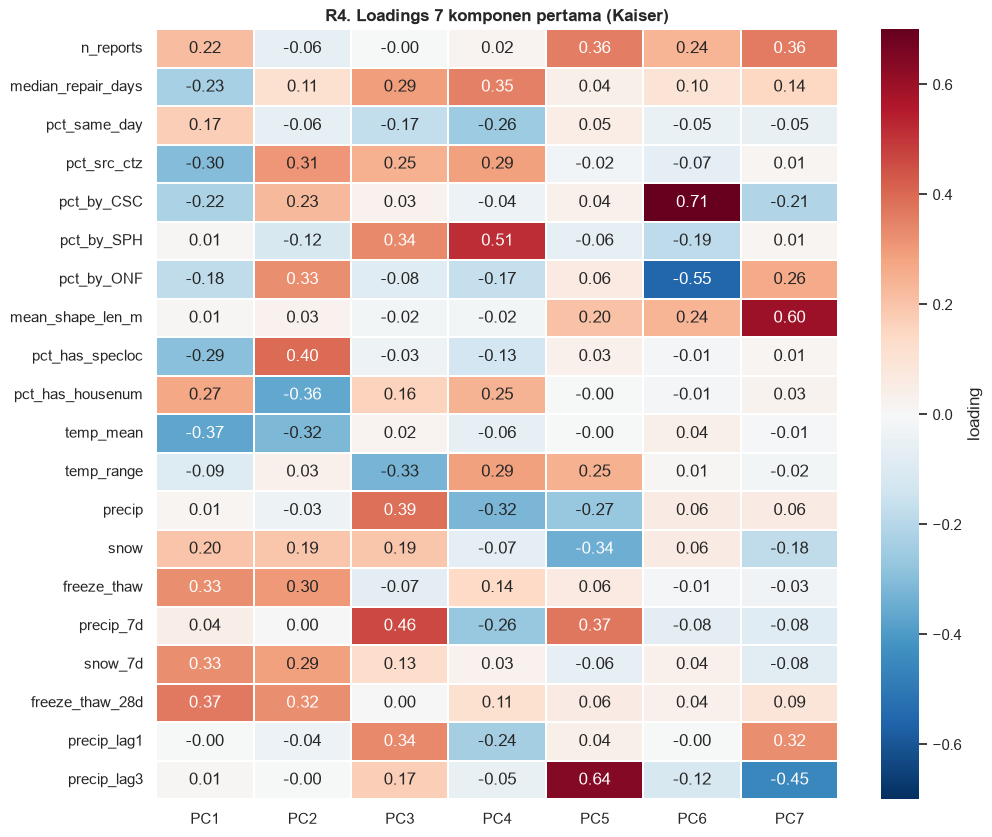

In [12]:
N_INTERP = k_kaiser
loadings = pd.DataFrame(pca.components_.T, index=PCA_FEATURES,
                        columns=[f"PC{i+1}" for i in range(len(PCA_FEATURES))])

fig, ax = plt.subplots(figsize=(11, 10))
sns.heatmap(loadings.iloc[:, :N_INTERP], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.7, vmax=.7,
            linewidths=.3, cbar_kws={"label": "loading"}, ax=ax)
ax.set_title(f"R4. Loadings {N_INTERP} komponen pertama (Kaiser)")
savefig("R4_loadings_heatmap")
plt.show()

In [13]:
def describe_pc(col, n=4):
    s = loadings[col]
    top = s.reindex(s.abs().sort_values(ascending=False).index)[:n]
    return ", ".join(f"{'+' if v > 0 else '−'}{k}" for k, v in top.items())

pc_table = pd.DataFrame({
    "% varians": eig["% varians"].iloc[:N_INTERP].round(1).values,
    "fitur dominan (tanda loading)": [describe_pc(c) for c in loadings.columns[:N_INTERP]],
}, index=loadings.columns[:N_INTERP])
pc_table

,% varians,fitur dominan (tanda loading)
PC1,17.800,"+freeze_thaw_28d, −temp_mean, +freeze_thaw, +s..."
PC2,11.800,"+pct_has_specloc, −pct_has_housenum, +pct_by_O..."
PC3,10.400,"+precip_7d, +precip, +precip_lag1, +pct_by_SPH"
PC4,8.900,"+pct_by_SPH, +median_repair_days, −precip, +pc..."
PC5,6.200,"+precip_lag3, +precip_7d, +n_reports, −snow"
PC6,5.700,"+pct_by_CSC, −pct_by_ONF, +mean_shape_len_m, +..."
PC7,5.300,"+mean_shape_len_m, −precip_lag3, +n_reports, +..."


**Penamaan komponen** (berdasarkan fitur dengan |loading| terbesar):

| PC | Nama | Makna nilai tinggi |
|---|---|---|
| PC1 | **Musim dingin & beku-cair** | Banyak hari beku-cair (28 hari), salju 7 hari, suhu rendah, dan porsi laporan warga (CTZ) lebih kecil |
| PC2 | **Cara pencatatan lokasi** | Laporan lebih sering memakai catatan lokasi (`SpecLoc`) daripada nomor rumah, porsi instansi ONF tinggi, ditambah komponen musim dingin |
| PC3 | **Hujan** | Presipitasi hari ini, 7 hari, dan kemarin tinggi; rentang suhu harian kecil (hari mendung) |
| PC4 | **Instansi SPH & durasi perbaikan** | Porsi instansi SPH tinggi, perbaikan lebih lama |
| PC5 | **Hujan tertunda & volume laporan** | Hujan 3 hari sebelumnya dan jumlah laporan tinggi |

PC6 dan seterusnya didominasi satu atau dua fitur operasional (komposisi instansi, panjang segmen), sehingga maknanya lebih sempit.

> Tanda (+/−) sebuah komponen bersifat arbitrer. Yang bermakna adalah **fitur mana yang searah dan mana yang berlawanan** di dalam komponen yang sama.

### 4.5 Skor PCA: biplot & pola musim/borough

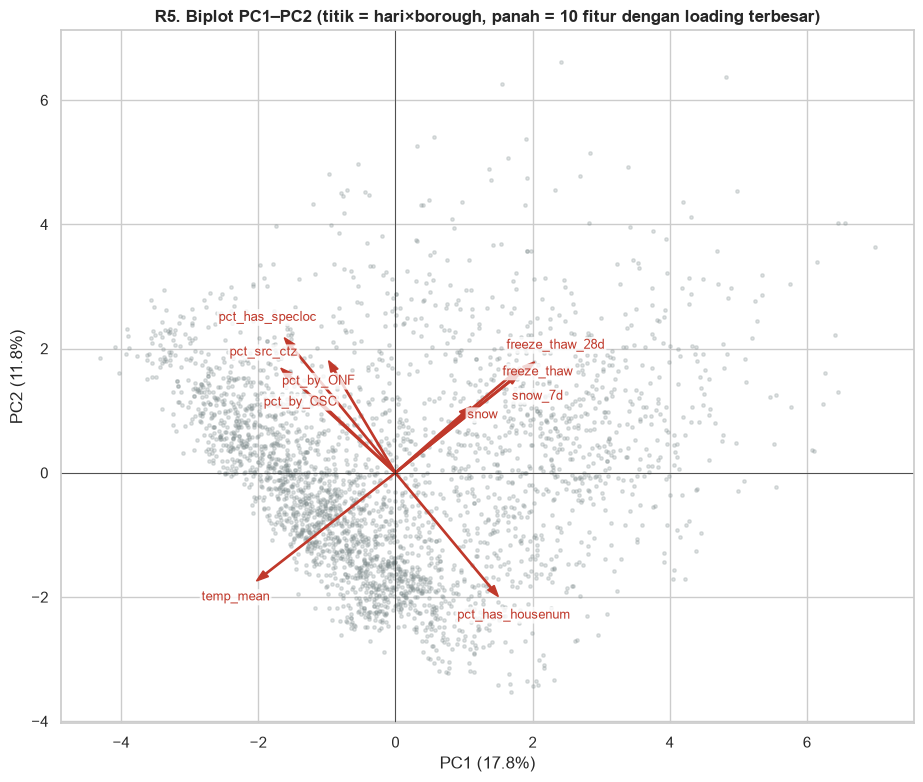

In [14]:
scores = pd.DataFrame(pca.transform(Z), columns=loadings.columns, index=data.index)
sample = scores.join(data[["season", "Boro"]]).sample(3000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(sample["PC1"], sample["PC2"], s=6, alpha=.25, color="#7f8c8d")
arrow_scale = 5.5
top_feats = (loadings[["PC1", "PC2"]].pow(2).sum(axis=1)).sort_values(ascending=False).index[:10]
placed = []
for f in top_feats:
    lx, ly = loadings.loc[f, "PC1"] * arrow_scale, loadings.loc[f, "PC2"] * arrow_scale
    ax.arrow(0, 0, lx, ly, color="#c0392b", width=.02, head_width=.12, length_includes_head=True)
    tx, ty = lx * 1.15, ly * 1.15
    while any(abs(tx - px) < 1.3 and abs(ty - py) < 0.3 for px, py in placed):   # geser label yang bertumpuk
        ty -= 0.3
    placed.append((tx, ty))
    ax.text(tx, ty, f, fontsize=9, color="#c0392b", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.8))
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
ax.set_xlabel(f"PC1 ({eig.loc['PC1', '% varians']:.1f}%)"); ax.set_ylabel(f"PC2 ({eig.loc['PC2', '% varians']:.1f}%)")
ax.set_title("R5. Biplot PC1–PC2 (titik = hari×borough, panah = 10 fitur dengan loading terbesar)")
savefig("R5_biplot")
plt.show()

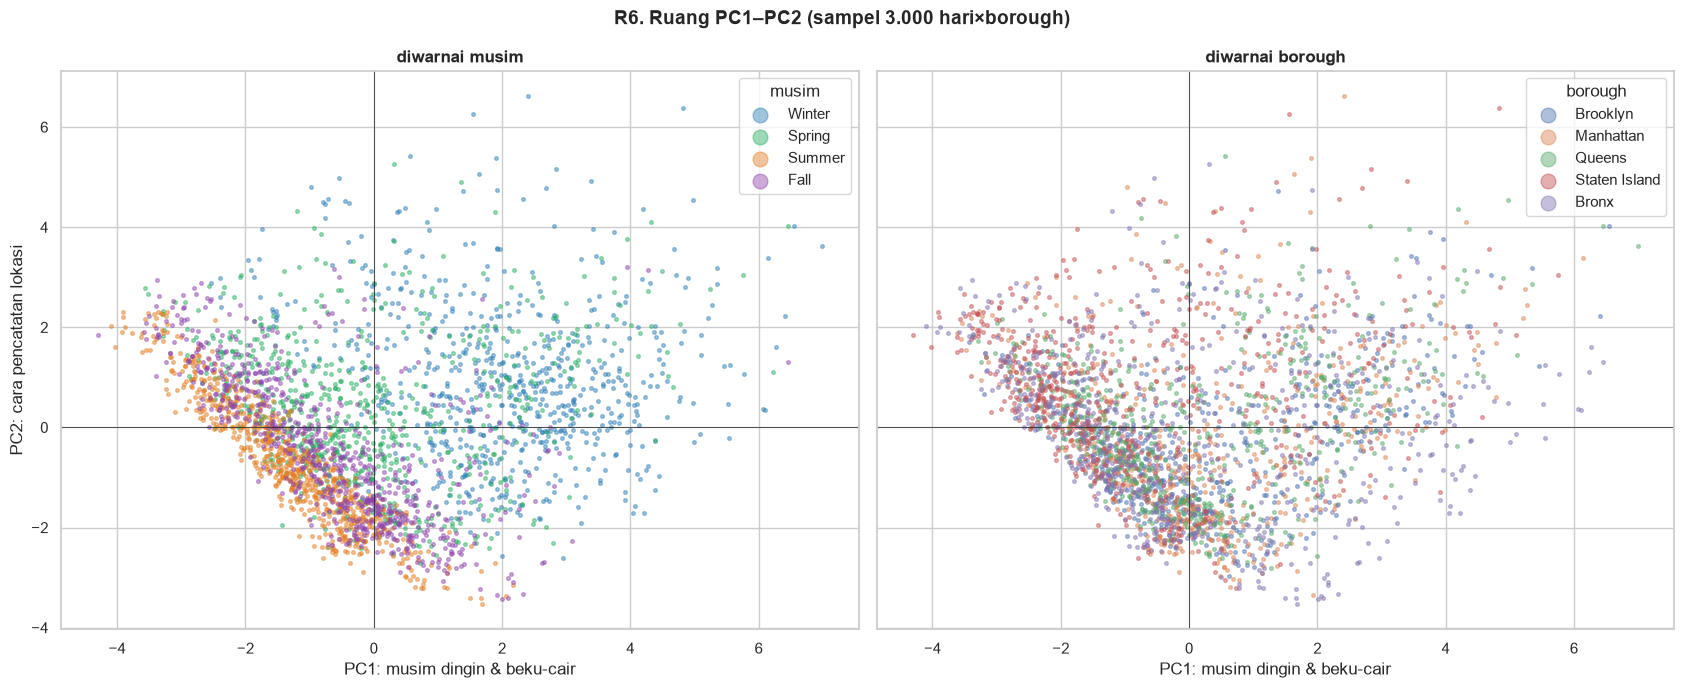

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)
for s in SEASON_ORDER:
    g = sample[sample["season"] == s]
    axes[0].scatter(g["PC1"], g["PC2"], s=7, alpha=.45, color=SEASON_COLOR[s], label=s)
axes[0].legend(markerscale=4, title="musim"); axes[0].set_title("diwarnai musim")
for b, g in sample.groupby("Boro", observed=True):
    axes[1].scatter(g["PC1"], g["PC2"], s=7, alpha=.45, label=BORO_NAME[b])
axes[1].legend(markerscale=4, title="borough"); axes[1].set_title("diwarnai borough")
for ax in axes:
    ax.set_xlabel("PC1: musim dingin & beku-cair"); ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
axes[0].set_ylabel("PC2: cara pencatatan lokasi")
fig.suptitle("R6. Ruang PC1–PC2 (sampel 3.000 hari×borough)", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("R6_pc_scatter_season_boro")
plt.show()

In [16]:
# Konfirmasi numerik: rata-rata skor PC per musim dan per borough
summary_season = scores[["PC1", "PC2", "PC3"]].groupby(data["season"]).mean().loc[SEASON_ORDER]
summary_boro = scores[["PC1", "PC2", "PC3"]].groupby(data["Boro"].map(BORO_NAME)).mean()
display(summary_season.round(2)); display(summary_boro.round(2))

,PC1,PC2,PC3
season,,,
Winter,2.010,0.910,-0.120
Spring,-0.040,0.360,0.170
Summer,-1.210,-0.780,0.190
Fall,-0.660,-0.440,-0.250


,PC1,PC2,PC3
Boro,,,
Brooklyn,0.360,-0.390,0.040
Manhattan,0.210,-0.300,-0.060
Queens,0.120,0.030,-0.100
Staten Island,-0.650,0.700,0.020
Bronx,-0.040,-0.040,0.100


**Interpretasi:**
- Pada **PC1**, titik-titik **musim dingin terpisah jelas** dari musim panas (rata-rata skor +2,0 vs −1,2), sedangkan musim semi dan gugur berada di tengah. PC1 memang merangkum sumbu musim.
- PC1 juga memuat `pct_src_ctz` dengan tanda berlawanan: **di musim dingin porsi laporan warga lebih rendah** (±61% vs ±80% di musim semi), sehingga lebih banyak perbaikan diinisiasi internal (YRD).
- Warna **borough** bertumpuk di PC1, karena semua borough memakai data cuaca yang sama (1 titik). Borough mulai berbeda di **PC2** (karakter pencatatan laporan). **Staten Island** paling tinggi di PC2 (+0,70): laporan di sana paling sering memakai catatan lokasi (±49% vs ±24% di Brooklyn) dan instansi ONF.

### 4.6 Rekonstruksi: berapa informasi yang hilang?

Data dikembalikan dari *k* komponen ke 20 fitur asli (`inverse_transform`), lalu dihitung **reconstruction error** (MSE pada skala z-score). Karena setiap fitur bervariansi 1, error ini sama dengan porsi varians yang dibuang.

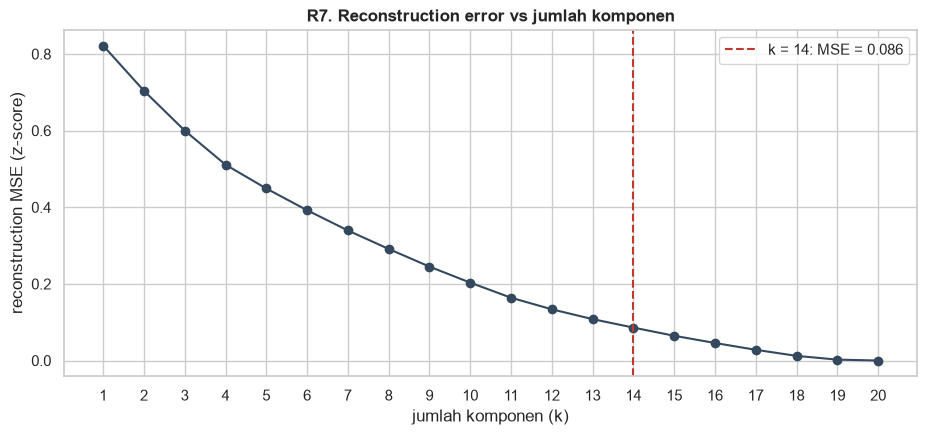

MSE rekonstruksi k=14: 0.0859  (= 1 − 0.9141 varians dipertahankan)
Fitur yang paling sulit direkonstruksi: {'pct_has_specloc': 0.254, 'pct_has_housenum': 0.198, 'precip_7d': 0.179}


In [17]:
recon = []
for k in range(1, len(PCA_FEATURES) + 1):
    p = PCA(n_components=k).fit(Z)
    Z_hat = p.inverse_transform(p.transform(Z))
    recon.append({"k": k, "mse": np.mean((Z.values - Z_hat) ** 2)})
recon = pd.DataFrame(recon).set_index("k")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(recon.index, recon["mse"], "o-", color="#34495e")
ax.axvline(K, color="#c0392b", ls="--", label=f"k = {K}: MSE = {recon.loc[K, 'mse']:.3f}")
ax.set_xlabel("jumlah komponen (k)"); ax.set_ylabel("reconstruction MSE (z-score)")
ax.set_xticks(recon.index)
ax.set_title("R7. Reconstruction error vs jumlah komponen")
ax.legend()
savefig("R7_reconstruction_error")
plt.show()

print(f"MSE rekonstruksi k={K}: {recon.loc[K, 'mse']:.4f}  (= 1 − {cum[K-1]/100:.4f} varians dipertahankan)")
per_feat = pd.Series(np.mean((Z.values - PCA(n_components=K).fit(Z).inverse_transform(PCA(n_components=K).fit(Z).transform(Z))) ** 2, axis=0),
                     index=PCA_FEATURES).sort_values(ascending=False)
print("Fitur yang paling sulit direkonstruksi:", per_feat.head(3).round(3).to_dict())

## 5. PCA vs Feature Selection

Tahap integrasi sudah melakukan **feature selection**: membuang atribut redundan berdasarkan korelasi. Seberapa banyak informasi yang dipertahankan dibanding PCA?

- **Feature selection**: informasi dari 27 fitur (semua fitur integrasi dikurangi low-variance) yang tertangkap oleh 20 fitur terpilih, diukur dengan R² regresi linear dari fitur terpilih ke semua fitur.
- **PCA pada 27 fitur** vs **PCA pada 20 fitur terpilih**: berapa komponen yang dibutuhkan untuk 90% varians?

In [18]:
FULL_PCA = [f for f in FEATURES_FULL if f not in LOW_VAR]
Z_full = pd.DataFrame(StandardScaler().fit_transform(prepare(data_full, FULL_PCA)), columns=FULL_PCA)
pca_full = PCA().fit(Z_full)
cum_full = pca_full.explained_variance_ratio_.cumsum() * 100
k90_full = int(np.argmax(cum_full >= 90) + 1)

# Informasi yang dipertahankan feature selection (R² total)
kept = [f for f in FULL_PCA if f in PCA_FEATURES]
pred = LinearRegression().fit(Z_full[kept], Z_full).predict(Z_full[kept])
retained_sel = (1 - ((Z_full.values - pred) ** 2).sum() / (Z_full.values ** 2).sum()) * 100

comparison = pd.DataFrame({
    "metode": ["PCA pada 27 fitur (tanpa feature selection)", "Feature selection (buang redundan)",
               "Feature selection → PCA (dipakai)"],
    "dimensi": [f"27 → {k90_full}", f"27 → {len(kept)}", f"27 → {len(kept)} → {K}"],
    "% informasi dari 27 fitur": [cum_full[k90_full - 1], retained_sel, retained_sel * cum[K - 1] / 100],
    "fitur masih bisa dibaca?": ["tidak (kombinasi linear)", "ya (fitur asli)", "tidak (kombinasi linear)"],
})
display(comparison.round(1))
print(f"Komponen untuk 90% varians: 27 fitur → {k90_full} | 20 fitur terpilih → {K}")

,metode,dimensi,% informasi dari 27 fitur,fitur masih bisa dibaca?
0,PCA pada 27 fitur (tanpa feature selection),27 → 14,90.200,tidak (kombinasi linear)
1,Feature selection (buang redundan),27 → 20,96.100,ya (fitur asli)
2,Feature selection → PCA (dipakai),27 → 20 → 14,87.800,tidak (kombinasi linear)


Komponen untuk 90% varians: 27 fitur → 14 | 20 fitur terpilih → 14


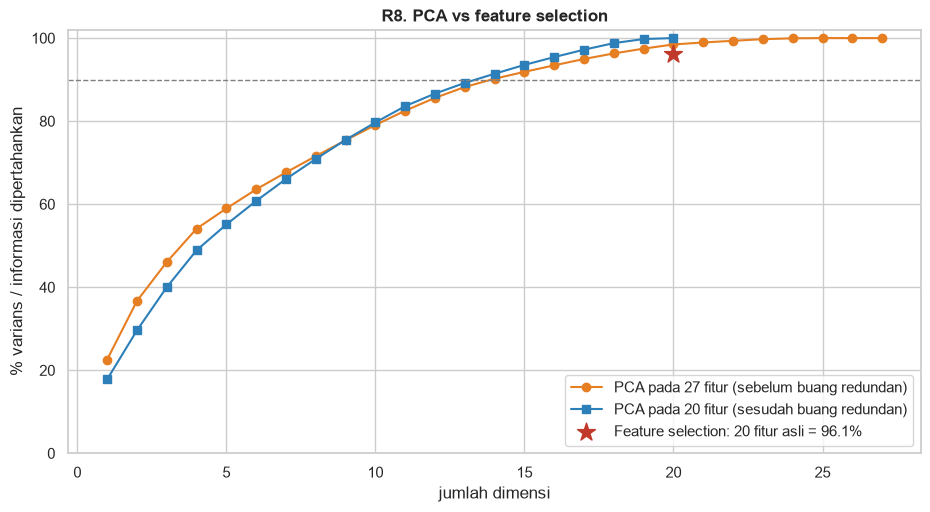

In [19]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(range(1, len(cum_full) + 1), cum_full, "o-", color="#e67e22", label=f"PCA pada {len(FULL_PCA)} fitur (sebelum buang redundan)")
ax.plot(range(1, len(cum) + 1), cum, "s-", color="#2c7fb8", label=f"PCA pada {len(PCA_FEATURES)} fitur (sesudah buang redundan)")
ax.scatter([len(kept)], [retained_sel], s=180, marker="*", color="#c0392b", zorder=5,
           label=f"Feature selection: {len(kept)} fitur asli = {retained_sel:.1f}%")
ax.axhline(90, color="grey", ls="--", lw=1)
ax.set_xlabel("jumlah dimensi"); ax.set_ylabel("% varians / informasi dipertahankan")
ax.set_title("R8. PCA vs feature selection")
ax.legend(loc="lower right"); ax.set_ylim(0, 102)
savefig("R8_pca_vs_feature_selection")
plt.show()

**Temuan:**
- PCA pada **27 fitur** (belum dibuang redundansinya) dan pada **20 fitur terpilih** membutuhkan jumlah komponen **yang hampir sama** untuk 90% varians. PCA secara otomatis "menyerap" fitur yang redundan ke komponen yang sama.
- **Feature selection** mempertahankan sekitar 96% informasi dengan **fitur asli yang tetap bisa dibaca**. PCA memampatkan lebih jauh, tetapi komponennya adalah kombinasi linear yang harus diinterpretasi lewat loadings.
- Kedua teknik **saling melengkapi**: feature selection membuat hasil lebih mudah dijelaskan, sedangkan PCA memampatkan sisa korelasi dan menghasilkan komponen yang **tidak berkorelasi satu sama lain**.

In [20]:
# Bukti: skor PCA tidak berkorelasi satu sama lain
pc_corr = scores.iloc[:, :K].corr()
print("Korelasi maksimum antar-PC (di luar diagonal):", np.abs(pc_corr.values[~np.eye(K, dtype=bool)]).max().round(6))

Korelasi maksimum antar-PC (di luar diagonal): 0.0


## 6. Numerosity Reduction

Selain mengurangi **kolom** (dimensi), data reduction juga bisa mengurangi **baris**, dengan syarat pola datanya tetap terjaga.

### 6.1 Agregasi harian → mingguan

In [21]:
SUM_COLS = ["n_reports"]
weekly = (data.assign(week=data["date"].dt.to_period("W").dt.start_time)
              .groupby(["week", "Boro"], observed=True)
              .agg({**{c: "sum" for c in SUM_COLS}, **{c: "mean" for c in FEATURES if c not in SUM_COLS}})
              .reset_index())
print(f"Harian: {len(data):,} baris → mingguan: {len(weekly):,} baris ({len(data)/len(weekly):.1f}× lebih sedikit)")

# Apakah struktur korelasi tetap terjaga?
c_daily  = data[PCA_FEATURES].corr("spearman")
c_weekly = weekly[PCA_FEATURES].corr("spearman")
iu = np.triu_indices(len(PCA_FEATURES), 1)
sim = np.corrcoef(c_daily.values[iu], c_weekly.values[iu])[0, 1]
print(f"Kemiripan matriks korelasi harian vs mingguan (r antar-elemen): {sim:.3f}")

pca_w = PCA().fit(StandardScaler().fit_transform(prepare(weekly, PCA_FEATURES)))
cum_w = pca_w.explained_variance_ratio_.cumsum() * 100
print(f"Mingguan: PC1 = {cum_w[0]:.1f}% (harian {cum[0]:.1f}%), komponen untuk 90% = {int(np.argmax(cum_w >= 90) + 1)} (harian {K})")

Harian: 12,650 baris → mingguan: 1,815 baris (7.0× lebih sedikit)
Kemiripan matriks korelasi harian vs mingguan (r antar-elemen): 0.904
Mingguan: PC1 = 23.2% (harian 17.8%), komponen untuk 90% = 11 (harian 14)


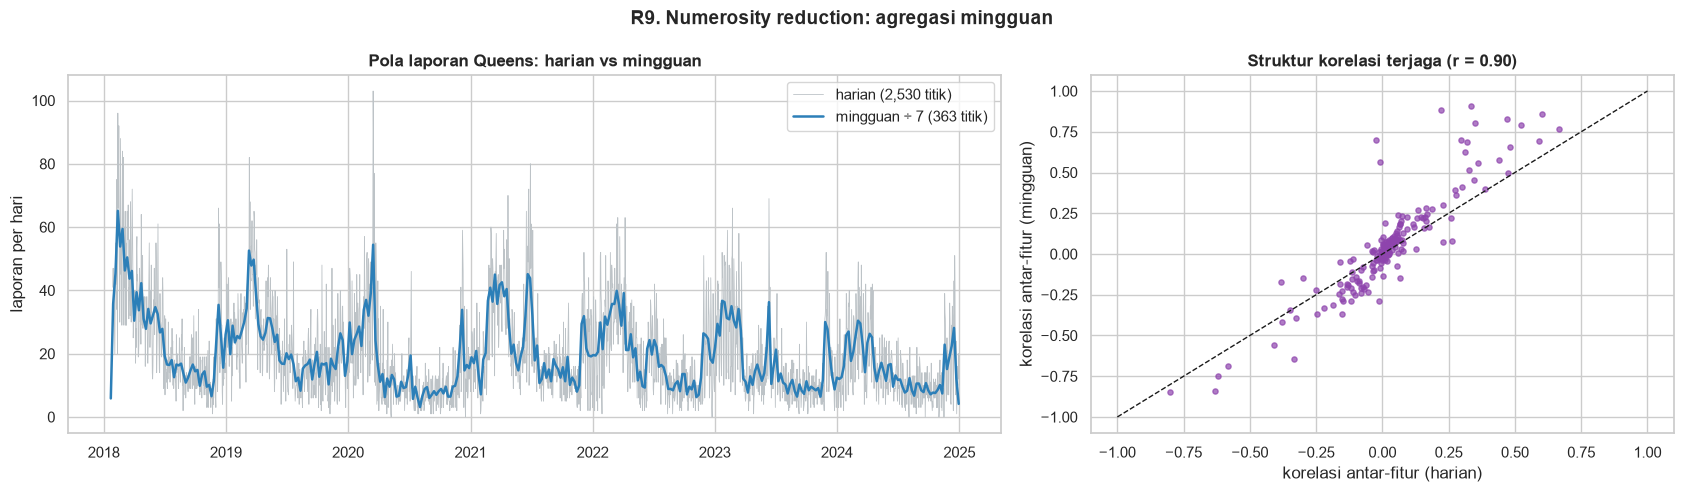

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.6, 1]})
b = "Q"
dq = data[data["Boro"] == b].set_index("date")["n_reports"]
wq = weekly[weekly["Boro"] == b].set_index("week")["n_reports"]
axes[0].plot(dq.index, dq, color="#bdc3c7", lw=.6, label=f"harian ({len(dq):,} titik)")
axes[0].plot(wq.index, wq / 7, color="#2c7fb8", lw=1.8, label=f"mingguan ÷ 7 ({len(wq):,} titik)")
axes[0].set_ylabel("laporan per hari"); axes[0].legend()
axes[0].set_title(f"Pola laporan {BORO_NAME[b]}: harian vs mingguan")

axes[1].scatter(c_daily.values[iu], c_weekly.values[iu], s=14, color="#8e44ad", alpha=.7)
axes[1].plot([-1, 1], [-1, 1], "k--", lw=1)
axes[1].set_xlabel("korelasi antar-fitur (harian)"); axes[1].set_ylabel("korelasi antar-fitur (mingguan)")
axes[1].set_title(f"Struktur korelasi terjaga (r = {sim:.2f})")
fig.suptitle("R9. Numerosity reduction: agregasi mingguan", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("R9_numerosity_weekly")
plt.show()

Agregasi mingguan mengurangi baris sekitar 7× dan tetap menjaga **tren musiman** serta **struktur korelasi** antar-fitur. Yang hilang adalah variasi harian (mis. efek hari kerja vs akhir pekan). Karena itu data harian tetap dipakai sebagai hasil utama.

### 6.2 Stratified sampling

Sampel 10% diambil **per strata borough × musim**, sehingga proporsi setiap borough dan musim sama dengan populasi. Kemiripan distribusi diuji dengan **Kolmogorov–Smirnov (KS)**: statistik D kecil dan p-value > 0,05 berarti distribusi sampel tidak berbeda signifikan dari populasi.

In [23]:
strat = (data.groupby(["Boro", "season"], observed=True, group_keys=False)
             .sample(frac=0.10, random_state=RANDOM_STATE))
print(f"Populasi {len(data):,} → sampel {len(strat):,} baris")

prop = pd.DataFrame({"populasi %": data.groupby(["Boro", "season"], observed=True).size() / len(data) * 100,
                     "sampel %": strat.groupby(["Boro", "season"], observed=True).size() / len(strat) * 100})
print("Selisih proporsi strata maksimum: {:.2f} poin persen".format((prop["populasi %"] - prop["sampel %"]).abs().max()))

ks = pd.DataFrame([{"fitur": f, "KS D": ks_2samp(data[f], strat[f]).statistic,
                    "p-value": ks_2samp(data[f], strat[f]).pvalue,
                    "selisih mean (%)": (strat[f].mean() - data[f].mean()) / (abs(data[f].mean()) + 1e-9) * 100}
                   for f in PCA_FEATURES]).set_index("fitur")
print("Fitur dengan distribusi berbeda signifikan (p < 0,05):", int((ks["p-value"] < 0.05).sum()), "dari", len(ks))
ks.sort_values("KS D", ascending=False).head(8).round(3)

Populasi 12,650 → sampel 1,260 baris
Selisih proporsi strata maksimum: 0.04 poin persen
Fitur dengan distribusi berbeda signifikan (p < 0,05): 0 dari 20


,KS D,p-value,selisih mean (%)
fitur,,,
mean_shape_len_m,0.033,0.171,1.196
pct_has_specloc,0.032,0.197,-3.706
precip_lag3,0.028,0.344,5.400
pct_same_day,0.027,0.365,-9.565
pct_by_CSC,0.021,0.692,-0.896
median_repair_days,0.021,0.700,-2.866
precip_7d,0.021,0.710,0.768
pct_src_ctz,0.020,0.747,-0.438


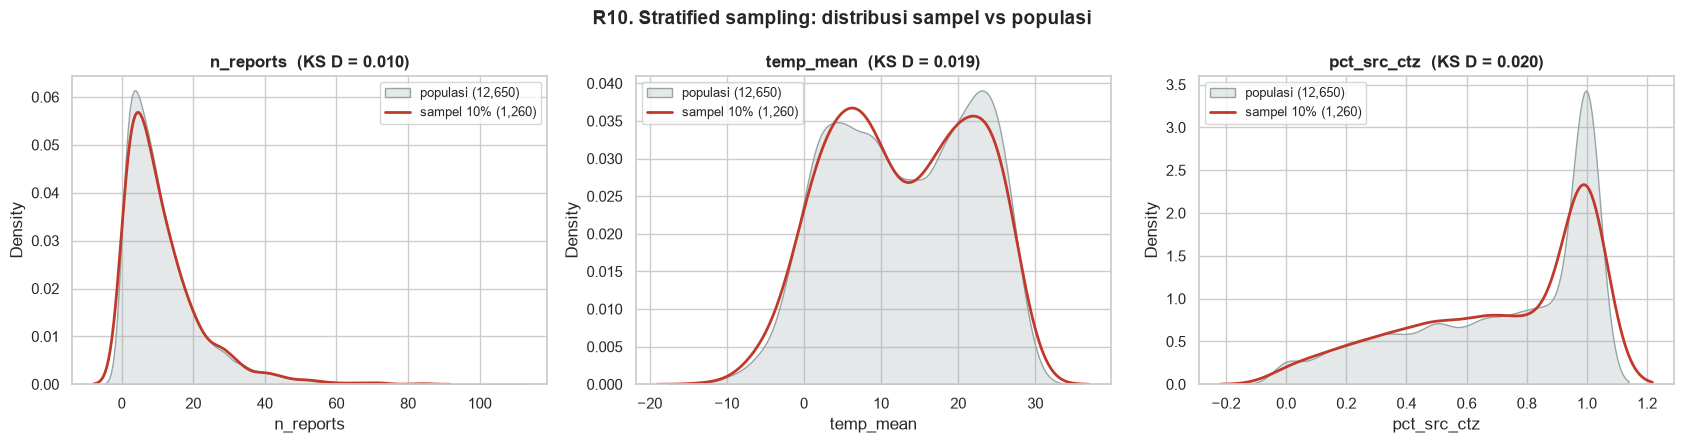

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, f in zip(axes, ["n_reports", "temp_mean", "pct_src_ctz"]):
    sns.kdeplot(data[f], ax=ax, fill=True, color="#95a5a6", label=f"populasi ({len(data):,})")
    sns.kdeplot(strat[f], ax=ax, color="#c0392b", lw=2, label=f"sampel 10% ({len(strat):,})")
    ax.set_title(f"{f}  (KS D = {ks.loc[f, 'KS D']:.3f})"); ax.legend(fontsize=9)
fig.suptitle("R10. Stratified sampling: distribusi sampel vs populasi", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("R10_stratified_sampling")
plt.show()

## 7. Simpan Hasil Reduksi

In [25]:
pc_cols = [f"PC{i+1}" for i in range(K)]
pca_result = pd.concat([data[["date", "Boro", "season", "month", "is_weekend"]].reset_index(drop=True),
                        scores[pc_cols].reset_index(drop=True)], axis=1)
pca_result.to_parquet(OUT_DIR / "pca_result.parquet", index=False)
pca_result.to_csv(OUT_DIR / "pca_result.csv", index=False, date_format="%Y-%m-%d")
loadings[pc_cols].to_csv(OUT_DIR / "pca_loadings.csv", index_label="fitur")
eig.to_csv(OUT_DIR / "pca_explained_variance.csv", index_label="komponen")

print("pca_result             :", pca_result.shape)
print("pca_loadings.csv       :", loadings[pc_cols].shape)
print("pca_explained_variance :", eig.shape)

pca_result             : (12650, 19)
pca_loadings.csv       : (20, 14)
pca_explained_variance : (20, 3)


## 8. Ringkasan End-to-End & Kesimpulan

In [26]:
clean_log = pd.read_csv(OUT_DIR / "cleaning_log.csv")
raw_rows, clean_rows = int(clean_log["rows"].iloc[0]), int(clean_log["rows"].iloc[-1])

funnel = pd.DataFrame([
    ("Raw",               "work order (2010–2026)",      raw_rows,   15),
    ("Cleaning",          "work order (2010–2026)",      clean_rows, 27),
    ("Integration",       "hari × borough (2018–2024)",  len(data_full), len(FEATURES_FULL)),
    ("Buang redundan",    "hari × borough",              len(data),  len(FEATURES)),
    ("Low-variance",      "hari × borough",              len(data),  len(PCA_FEATURES)),
    ("PCA (90%)",         "hari × borough",              len(pca_result), K),
    ("Numerosity (mgg)",  "minggu × borough",            len(weekly), len(FEATURES)),
], columns=["tahap", "unit baris", "baris", "kolom / fitur numerik"])
funnel

,tahap,unit baris,baris,kolom / fitur numerik
0,Raw,work order (2010–2026),410488,15
1,Cleaning,work order (2010–2026),400961,27
2,Integration,hari × borough (2018–2024),12650,28
3,Buang redundan,hari × borough,12650,21
4,Low-variance,hari × borough,12650,20
5,PCA (90%),hari × borough,12650,14
6,Numerosity (mgg),minggu × borough,1815,21


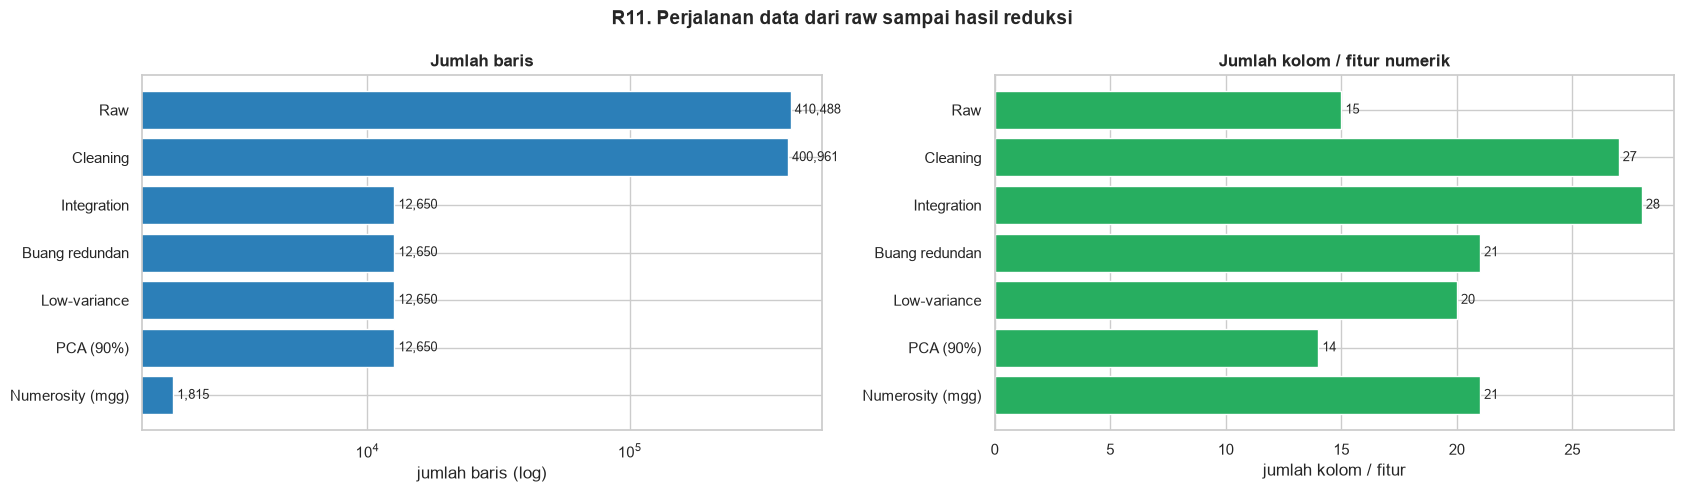

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].barh(funnel["tahap"][::-1], funnel["baris"][::-1], color="#2c7fb8")
axes[0].set_xscale("log"); axes[0].set_xlabel("jumlah baris (log)")
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:,}" for v in funnel["baris"][::-1]], padding=3, fontsize=9)
axes[0].set_title("Jumlah baris")
axes[1].barh(funnel["tahap"][::-1], funnel["kolom / fitur numerik"][::-1], color="#27ae60")
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=9)
axes[1].set_xlabel("jumlah kolom / fitur"); axes[1].set_title("Jumlah kolom / fitur numerik")
fig.suptitle("R11. Perjalanan data dari raw sampai hasil reduksi", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("R11_end_to_end_funnel")
plt.show()

### Kesimpulan

#### A. Kesimpulan preprocessing

**1. Data cleaning** (`data_cleaning.ipynb`, grafik C1–C10, D1–D11)
- Data work order NYC DOT **tidak siap pakai**: 65,5% `SpecLoc` dan 39,3% `HouseNum` kosong, ada **8.853 laporan ganda**, **574 perbaikan "selesai sebelum dilaporkan"**, 45 laporan sebelum 2010, dan segmen "BODY OF WATER" sepanjang 140.473 ft. Setelah cleaning, **97,7% data dipertahankan** (410.488 → 400.961 baris).
- **Redundansi internal dimanfaatkan untuk validasi dan imputasi**: `Boro` 100% konsisten dengan prefix `DefNum`, `DefNum` menyimpan tanggal input (jeda 0–6 hari), dan kode jalan di `OFT` memetakan 1:1 ke nama jalan.
- **Pemilihan metode outlier harus mengikuti bentuk distribusi**: pada durasi perbaikan (skewness 182), IQR biasa menandai 10,9% data dan MAD 19,8%, sedangkan **Log-IQR hanya 1,3%**. Durasi 0 hari **bukan** outlier.
- **Outlier ≠ error**: hujan 187,2 mm (2022-10-04) terbukti error setelah diverifikasi dengan stasiun NOAA (47 mm), sedangkan Badai Ida (111,5 mm) adalah kejadian nyata.

**2. Data integration** (`data_integration.ipynb`, grafik I1–I10)
- Integrasi menuntut penyelesaian **perbedaan granularitas** (work order → hari × borough), **perbedaan cakupan waktu** (filter ke 2018–2024), **hari tanpa laporan** (445 hari-borough), dan **perbedaan satuan** (feet → meter).
- Dari 28 fitur, **7 redundan** (|r| > 0,85) dan dibuang. **VIF** mengungkap kolinearitas yang tidak terlihat dari korelasi berpasangan (presipitasi = hujan + salju). Sesudah pembuangan, semua VIF < 10.
- **Chi-square**: sumber pelapor dan instansi penangan sangat terkait (Cramér's V = 0,74). Laporan YRD 99,6% ditangani YRD sendiri.

**3. Data reduction** (notebook ini, grafik R1–R11)
- **Scaling wajib** sebelum PCA: tanpa standardisasi, PC1 didominasi satu fitur bersatuan besar.
- PCA mereduksi fitur ke **k komponen yang mempertahankan ≥ 90% varians** (angka pasti di bagian 4.3). Reduksinya moderat karena redundansi sudah dibuang di tahap integrasi. PCA pada 27 fitur (tanpa pembuangan) membutuhkan jumlah komponen yang hampir sama.
- Komponen utama dapat diberi makna: **PC1 = musim dingin & beku-cair**, **PC2 = cara pencatatan lokasi**, **PC3 = hujan**.
- **Numerosity reduction**: agregasi mingguan (≈7× lebih sedikit baris) dan stratified sampling 10% tetap menjaga pola dan distribusi data.

#### B. Insight dari data yang sudah diproses
- Laporan lubang jalan memiliki **pola musiman yang kuat**: melonjak di akhir musim dingin hingga awal musim semi (rata-rata harian tertinggi di musim semi, ±15 laporan/borough/hari, vs ±7 di musim gugur), sesuai dengan jeda beberapa minggu setelah siklus beku-cair. PC1 (sumbu musim dingin & beku-cair) adalah komponen terbesar.
- **Di musim dingin, porsi laporan warga turun** (±61% vs ±80% di musim semi): perbaikan lebih banyak diinisiasi internal oleh instansi.
- Korelasi laporan mingguan dengan hari beku-cair **3 minggu sebelumnya** mencapai sekitar 0,57, tetapi **sebagian besar merupakan efek musim**. Di dalam musim dingin saja korelasinya sedang (±0,3). **Hujan saja hampir tidak berpengaruh.**
- **Sumber pelapor menentukan alur penanganan**: laporan warga (CTZ) disebar ke instansi SPH/CSC/ONF, sedangkan laporan internal YRD ditangani YRD sendiri.

#### C. Keterbatasan
- Hasil adalah **asosiasi, bukan sebab-akibat** (data observasional).
- Cuaca berasal dari **1 titik** untuk seluruh NYC, sehingga sama untuk kelima borough.
- Data cuaca adalah **data model**: 3 hari over-estimate sudah dikoreksi, tetapi hujan badai lokal cenderung **di bawah nilai sebenarnya** (Ida: 111,5 vs 181,1 mm) dan dibiarkan.
- Arti sebagian kode `InitBy`/`Source` tidak terdokumentasi resmi.

In [28]:
# Angka PCA untuk melengkapi kesimpulan poin A.3
print(f"PCA: {len(PCA_FEATURES)} fitur → {K} komponen ({cum[K-1]:.1f}% varians), "
      f"Kaiser {k_kaiser} komponen ({cum[k_kaiser-1]:.1f}%), elbow {k_elbow} komponen ({cum[k_elbow-1]:.1f}%)")
print(f"PCA 27 fitur butuh {k90_full} komponen untuk 90% | feature selection mempertahankan {retained_sel:.1f}%")
print(f"PC1 = {eig.loc['PC1', '% varians']:.1f}% varians | agregasi mingguan: {len(data)/len(weekly):.1f}× lebih sedikit baris, "
      f"kemiripan korelasi {sim:.2f}")

PCA: 20 fitur → 14 komponen (91.4% varians), Kaiser 7 komponen (66.1%), elbow 5 komponen (55.1%)
PCA 27 fitur butuh 14 komponen untuk 90% | feature selection mempertahankan 96.1%
PC1 = 17.8% varians | agregasi mingguan: 7.0× lebih sedikit baris, kemiripan korelasi 0.90


## 9. Checklist Kriteria Tugas

| Kriteria tugas | Dipenuhi di | Bukti (grafik / output) |
|---|---|---|
| Dataset open data, **tidak bersih**, perlu preprocessing | Cleaning bag. 1–4 | C1–C8, `output/data_quality_issues.csv` (21 masalah) |
| Dataset **unik** | - | NYC DOT Street Pothole Work Orders + cuaca Open-Meteo NYC (dikonfirmasi unik oleh mahasiswa) |
| **Data cleaning**: missing value | Cleaning bag. 6–7 | D2, D11, imputasi berbasis redundansi `OFT`/`OnPrimName`, flag `has_*` |
| **Data cleaning**: duplikat | Cleaning bag. 8 | D3, 8.853 duplikat logis |
| **Data cleaning**: deteksi & hapus outlier | Cleaning bag. 10–11 | D4–D9: rule-based + IQR/Z/MAD/Log-IQR/Isolation Forest + verifikasi NOAA |
| **Data integration**: menggabungkan sumber | Integrasi bag. 2–6 | I1, I2, merge `validate="many_to_one"`, 0 duplikat, 0 NaN |
| **Data integration**: atribut redundan (korelasi/kovarians) | Integrasi bag. 7–9 | I3–I8: Pearson, Spearman, kovarians, VIF, chi-square |
| **Data reduction**: PCA | Reduction bag. 2–5 | R1–R8: transformasi, scaling, 3 kriteria k, loadings, biplot, rekonstruksi |
| Data reduction tambahan | Reduction bag. 2.1, 6 | Low-variance filter, R9–R10 (mingguan, stratified sampling) |
| **Visualisasi hasil preprocessing** | semua notebook | C1–C10, D1–D11, I1–I10, R1–R11 (sebelum vs sesudah di tiap tahap) |